# Taller 18b — Segmentación de pacientes con K-means

**Curso:** Minería de Datos (2016325)  
**Estudiante:** Carlos Ernesto Araujo Romero  
**Datos:** `data/heart.csv` — 1.025 registros, 13 variables clínicas y la respuesta `target`  
**Herramientas:** Python, pandas, scikit-learn y matplotlib

Este notebook desarrolla el taller de aprendizaje no supervisado: revisa los rangos de las variables, muestra qué pasa si no se escalan, estandariza, elige el número de grupos con la inercia y la silueta, ajusta K-means con muchas inicializaciones, perfila y nombra los grupos y, al final, los cruza con `target`, que se mantuvo apartado durante todo el ajuste.

> **En Colab:** ejecute las celdas en orden. Si el archivo no está en `data/heart.csv`, la celda de carga le pedirá subir `heart.csv`.

## 1. Carga y exploración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency
from IPython.display import display

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

# En Colab el archivo no viaja con el notebook: se busca en varias rutas y,
# si no aparece, se pide subirlo.
RUTA = Path("data/heart.csv")
if not RUTA.exists():
    RUTA = Path("taller_aprendizaje_nosupervisado/data/heart.csv")
if not RUTA.exists():
    RUTA = Path("heart.csv")
if not RUTA.exists():
    from google.colab import files
    subidos = files.upload()
    RUTA = Path(next(iter(subidos)))

df = pd.read_csv(RUTA)
X = df.drop(columns="target")
y = df["target"]

print("Archivo:", RUTA)
print("Dimensiones:", df.shape)
print("Valores faltantes:", int(df.isna().sum().sum()))
print("\nFrecuencia de target:")
print(y.value_counts().sort_index().to_string())
display(df.head())

Archivo: data/heart.csv
Dimensiones: (1025, 14)
Valores faltantes: 0

Frecuencia de target:
target
0    499
1    526


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


**Variables:** `age` edad; `sex` sexo (1 hombre); `cp` tipo de dolor torácico (0–3); `trestbps` presión arterial en reposo (mm Hg); `chol` colesterol (mg/dl); `fbs` glucosa en ayunas alta (1 sí); `restecg` ECG en reposo (0–2); `thalach` frecuencia cardíaca máxima; `exang` angina inducida por ejercicio (1 sí); `oldpeak` depresión del ST inducida por ejercicio; `slope` pendiente del ST (0–2); `ca` número de vasos principales afectados (0–4); `thal` resultado del talio (0–3); `target` respuesta apartada.

No hay valores faltantes y `target` está relativamente balanceado (526 casos con 1 y 499 con 0). También hay 723 filas duplicadas exactas (302 filas únicas): se conservan porque el archivo es el insumo del taller, pero se advierte en las limitaciones.

In [2]:
resumen = pd.DataFrame({
    "min": X.min(),
    "max": X.max(),
    "desv_est": X.std(),
})
resumen["rango"] = resumen["max"] - resumen["min"]
resumen = resumen.sort_values("rango", ascending=False)
display(resumen.round(2))

,min,max,desv_est,rango
chol,126.0,564.0,51.59,438.0
thalach,71.0,202.0,23.01,131.0
trestbps,94.0,200.0,17.52,106.0
age,29.0,77.0,9.07,48.0
oldpeak,0.0,6.2,1.18,6.2
ca,0.0,4.0,1.03,4.0
cp,0.0,3.0,1.03,3.0
thal,0.0,3.0,0.62,3.0
restecg,0.0,2.0,0.53,2.0
slope,0.0,2.0,0.62,2.0


## 2. Los rangos y el problema de escalar

K-means minimiza la suma de distancias euclidianas al cuadrado. Con las variables en su escala original, esa suma mezcla unidades que no son comparables: años, mg/dl, mm Hg y milímetros de depresión del ST.

Los rangos muestran el problema:

| Variable | Rango aproximado | Unidad |
|---|---:|---|
| `chol` | 126 – 564 (438) | mg/dl |
| `thalach` | 71 – 202 (131) | lpm |
| `trestbps` | 94 – 200 (106) | mm Hg |
| `age` | 29 – 77 (48) | años |
| `oldpeak` | 0,0 – 6,2 (6,2) | mm |
| binarias (`sex`, `fbs`, `exang`) | 0 – 1 (1) | 0/1 |
| códigos (`cp`, `restecg`, `slope`, `ca`, `thal`) | 0 – 2 o 0 – 4 | código |

Una diferencia de 100 mg/dl de colesterol aporta \(100^2 = 10.000\) a la distancia al cuadrado, mientras que una diferencia de 1 mm en `oldpeak` aporta \(1^2 = 1\). Por eso, sin escalar, el colesterol domina la distancia y las variables binarias o `oldpeak` casi no influyen. Peor aún, si el colesterol se midiera en mmol/L, los grupos cambiarían aunque los pacientes fueran los mismos.

Para comprobarlo, ajustamos K-means con K=2 sobre `X` sin escalar:

In [3]:
km_sin = KMeans(n_clusters=2, n_init=50, random_state=42)
lab_sin = km_sin.fit_predict(X)

perfil_sin = X.groupby(lab_sin).mean().T
perfil_sin.columns = [f"Grupo {c}" for c in perfil_sin.columns]
perfil_sin["Global"] = X.mean()
display(perfil_sin.round(1))

print(f"Silueta sin escalar: {silhouette_score(X, lab_sin):.3f}")
print(f"ARI frente a target: {adjusted_rand_score(y, lab_sin):.3f}")
print("Tamaños:", np.bincount(lab_sin))

,Grupo 0,Grupo 1,Global
age,56.8,53.1,54.4
sex,0.6,0.8,0.7
cp,0.8,1.0,0.9
trestbps,135.0,129.7,131.6
chol,299.2,216.0,246.0
fbs,0.1,0.2,0.1
restecg,0.4,0.6,0.5
thalach,145.0,151.4,149.1
exang,0.4,0.3,0.3
oldpeak,1.2,1.0,1.1


Silueta sin escalar: 0.397
ARI frente a target: 0.021
Tamaños: [370 655]


El resultado es un corte por colesterol: un grupo ronda los 299 mg/dl y el otro los 216 mg/dl, mientras que las demás variables cambian poco. La silueta es 0,397, pero **una silueta alta no significa mejores grupos**: la distancia está dominada por el colesterol y los grupos casi no se relacionan con `target` (ARI = 0,021). Es un artefacto de escala, no estructura clínica.

Por eso el resto del taller trabaja con las variables estandarizadas.

## 3. Escalado de las variables

Se aplica `StandardScaler`, que transforma cada variable como

\[
z_j = \frac{x_j - \bar{x}_j}{s_j},
\]

donde \(\bar{x}_j\) es la media y \(s_j\) la desviación estándar de la variable \(j\). El escalador se ajusta **solo con `X`**; `target` no participa. Así, cada variable queda con media 0 y desviación estándar 1, y una diferencia de una desviación estándar pesa igual en todas.

In [4]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)
Z = pd.DataFrame(Z, columns=X.columns, index=X.index)
display(Z.describe().T[["mean", "std", "min", "max"]].round(3))

,mean,std,min,max
age,-0.0,1.0,-2.805,2.489
sex,0.0,1.0,-1.512,0.662
cp,0.0,1.0,-0.916,1.999
trestbps,-0.0,1.0,-2.148,3.906
chol,-0.0,1.0,-2.327,6.167
fbs,-0.0,1.0,-0.419,2.387
restecg,-0.0,1.0,-1.004,2.787
thalach,-0.0,1.0,-3.397,2.300
exang,-0.0,1.0,-0.712,1.404
oldpeak,-0.0,1.0,-0.912,4.367


## 4. Elección de K: inercia y silueta para K = 2, …, 8

Para cada K se ajusta K-means con `n_init=50` y se calculan:

* **Inercia:** suma de distancias al cuadrado de cada punto a su centro. Siempre baja al aumentar K, así que se busca el “codo”.
* **Silueta media:** compara la distancia media dentro del grupo con la distancia media al grupo vecino. Va de -1 a 1; más alto indica grupos más compactos y separados.

In [5]:
inercia_k1 = KMeans(n_clusters=1, n_init=1, random_state=42).fit(Z).inertia_

filas = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=50, random_state=42)
    lab_k = km_k.fit_predict(Z)
    filas.append({
        "K": k,
        "Inercia": km_k.inertia_,
        "Silueta": silhouette_score(Z, lab_k),
    })

res = pd.DataFrame(filas).set_index("K")
anteriores = [inercia_k1] + res["Inercia"].tolist()[:-1]
res["Reducción (%)"] = [
    100 * (anterior - actual) / anterior
    for anterior, actual in zip(anteriores, res["Inercia"])
]
display(res.round(3))
print(f"Inercia con K=1: {inercia_k1:.2f}")

,Inercia,Silueta,Reducción (%)
K,,,
2,11245.052,0.170,15.609
3,10414.095,0.125,7.390
4,9689.665,0.132,6.956
5,9210.325,0.129,4.947
6,8874.950,0.131,3.641
7,8514.603,0.127,4.060
8,8217.545,0.140,3.489


Inercia con K=1: 13325.00


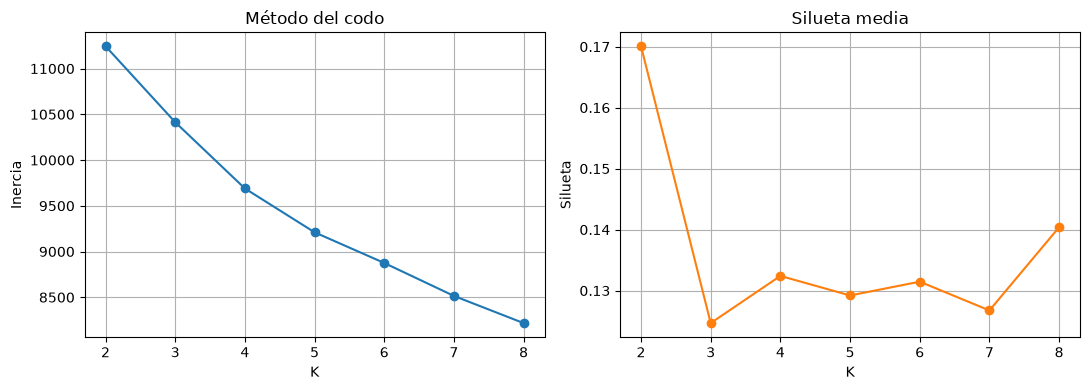

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(res.index, res["Inercia"], marker="o", color="tab:blue")
ax[0].set_title("Método del codo")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inercia")
ax[0].set_xticks(res.index)

ax[1].plot(res.index, res["Silueta"], marker="o", color="tab:orange")
ax[1].set_title("Silueta media")
ax[1].set_xlabel("K")
ax[1].set_ylabel("Silueta")
ax[1].set_xticks(res.index)

plt.tight_layout()
plt.show()

La inercia baja siempre, pero el salto grande ocurre al pasar de K=1 a K=2: de 13.325 a 11.245 (una reducción de 15,6 %). Después las reducciones son menores: 7,4 % al pasar a K=3, 7,0 % a K=4 y cada vez menos. La silueta máxima está en **K=2 (0,170)**; con K=3 baja a 0,125 y luego se mantiene alrededor de 0,13, con un repunte menor en K=8 (0,140).

Con el codo y, sobre todo, con la silueta, se elige **K=2**. Es el valor que mejor separa los grupos dentro del rango explorado, el más parsimonioso y el que produce perfiles clínicos interpretables. La silueta de 0,170 es modesta: hay solapamiento entre grupos, así que la segmentación es descriptiva y no una verdad natural de los datos.

## 5. Ajuste final de K-means (K=2, n_init=100)

`n_init=100` equivale al `nstart` alto de R: se prueban 100 inicializaciones aleatorias y se conserva la de menor inercia. Se fija `random_state=42` para que el resultado sea reproducible. Después se reordenan las etiquetas por `thalach` (mayor primero) para que el “Grupo 0” sea siempre el de mayor capacidad funcional y no dependa de la etiqueta arbitraria que asigna el algoritmo.

In [7]:
K = 2
km = KMeans(n_clusters=K, n_init=100, random_state=42)
lab = km.fit_predict(Z)

i_thalach = list(X.columns).index("thalach")
orden = np.argsort(km.cluster_centers_[:, i_thalach])[::-1]
mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
lab = np.array([mapa[x] for x in km.labels_])
centros = km.cluster_centers_[orden]

print("Tamaños:", np.bincount(lab))
print(f"Inercia: {km.inertia_:.2f}")
print(f"Silueta: {silhouette_score(Z, lab):.3f}")
display(pd.DataFrame(
    centros,
    columns=X.columns,
    index=["Grupo 0 (favorable)", "Grupo 1 (isquémico)"],
).round(2))

Tamaños: [653 372]
Inercia: 11245.05
Silueta: 0.170


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
Grupo 0 (favorable),-0.25,-0.08,0.39,-0.12,-0.07,-0.04,0.07,0.48,-0.46,-0.42,0.38,-0.31,-0.23
Grupo 1 (isquémico),0.43,0.15,-0.69,0.22,0.13,0.07,-0.12,-0.85,0.80,0.73,-0.66,0.55,0.40


In [8]:
arias = []
for semilla in range(5):
    lab_s = KMeans(n_clusters=2, n_init=100, random_state=semilla).fit_predict(Z)
    arias.append(adjusted_rand_score(lab, lab_s))
print("ARI frente a la solución final:", [round(a, 3) for a in arias])

ARI frente a la solución final: [1.0, 1.0, 1.0, 1.0, 1.0]


Los grupos quedan de 653 pacientes (63,7 %) y 372 (36,3 %). La solución es estable: al repetir con cinco semillas distintas y `n_init=100`, la partición es idéntica (ARI = 1,000).

## 6. Perfil de los grupos y nombres

Se describen los grupos con las variables en su escala original, para que las medias sean interpretables. En las variables binarias, la media se lee como proporción.

In [9]:
perfil = X.groupby(lab).mean().T
perfil.columns = ["Grupo 0 (favorable)", "Grupo 1 (isquémico)"]
perfil["Global"] = X.mean()
perfil["Diferencia (1 - 0)"] = perfil["Grupo 1 (isquémico)"] - perfil["Grupo 0 (favorable)"]
display(perfil.round(2))

tamanos = pd.Series(lab).value_counts().sort_index()
tabla_tamanos = pd.DataFrame({
    "n": tamanos,
    "porcentaje": (tamanos / len(lab) * 100).round(1),
})
tabla_tamanos.index = ["Grupo 0 (favorable)", "Grupo 1 (isquémico)"]
display(tabla_tamanos)

,Grupo 0 (favorable),Grupo 1 (isquémico),Global,Diferencia (1 - 0)
age,52.21,58.34,54.43,6.12
sex,0.66,0.76,0.70,0.11
cp,1.35,0.23,0.94,-1.12
trestbps,129.43,135.44,131.61,6.01
chol,242.20,252.67,246.00,10.46
fbs,0.13,0.17,0.15,0.04
restecg,0.57,0.47,0.53,-0.10
thalach,160.19,129.68,149.11,-30.51
exang,0.12,0.72,0.34,0.59
oldpeak,0.58,1.93,1.07,1.35


,n,porcentaje
Grupo 0 (favorable),653,63.7
Grupo 1 (isquémico),372,36.3


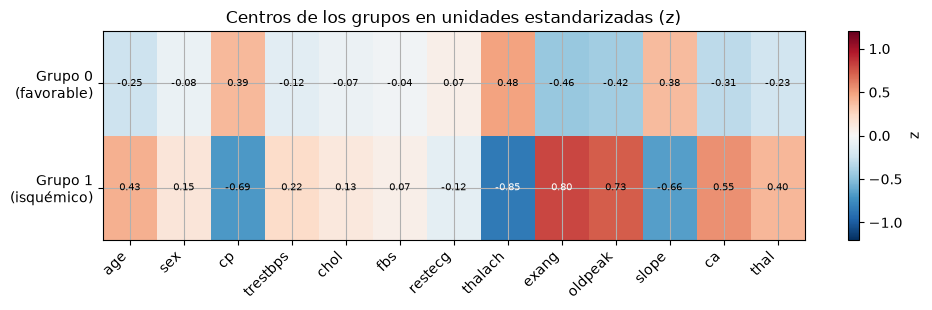

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(centros, aspect="auto", cmap="RdBu_r", vmin=-1.2, vmax=1.2)
ax.set_xticks(range(len(X.columns)))
ax.set_xticklabels(X.columns, rotation=45, ha="right")
ax.set_yticks(range(2))
ax.set_yticklabels(["Grupo 0\n(favorable)", "Grupo 1\n(isquémico)"])
for i in range(centros.shape[0]):
    for j in range(centros.shape[1]):
        valor = centros[i, j]
        color = "white" if abs(valor) > 0.8 else "black"
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=7, color=color)
ax.set_title("Centros de los grupos en unidades estandarizadas (z)")
plt.colorbar(im, ax=ax, label="z")
plt.tight_layout()
plt.show()

**Grupo 0 — “Perfil favorable / baja carga isquémica” (653 pacientes, 63,7 %).** Son pacientes más jóvenes (52,2 vs 58,3 años), con mayor frecuencia cardíaca máxima (160,2 vs 129,7 lpm), poca angina de esfuerzo (12 % vs 72 %), menor depresión del ST (`oldpeak` 0,58 vs 1,93), menos vasos afectados (`ca` 0,43 vs 1,32) y una pendiente del ST más ascendente (`slope` 1,62 vs 0,98). El 69,7 % tiene `thal=2` y el 39,4 % tiene `cp=2`; el grupo se reparte más entre tipos de dolor y no se concentra en `cp=0`.

**Grupo 1 — “Perfil isquémico de alto riesgo” (372 pacientes, 36,3 %).** Son mayores, con menor capacidad funcional (`thalach` bajo), angina de esfuerzo, depresión del ST, más vasos comprometidos y una pendiente del ST más plana. El 87,4 % tiene `cp=0`, el 66,7 % tiene `thal=3` y el 76,6 % tiene `slope=1`. Es el grupo con mayor carga de enfermedad y el que clínicamente se parece a un patrón isquémico.

Los nombres son descriptivos: resumen el perfil conjunto de las variables, no un diagnóstico. La interpretación de `cp`, `slope` y `thal` supone la codificación clásica de Cleveland; el archivo solo trae los códigos.

## 7. Cruce con la respuesta apartada (`target`)

`target` no se usó para escalar ni para ajustar K-means. Se incorpora ahora para responder si los grupos coinciden con la respuesta y qué encontró K-means que la respuesta no dice.

In [11]:
tabla = pd.crosstab(pd.Series(lab, name="Grupo"), y)
tabla.index = ["Grupo 0 (favorable)", "Grupo 1 (isquémico)"]
display(tabla)

filas = (pd.crosstab(lab, y, normalize="index") * 100).round(1)
filas.index = ["Grupo 0 (favorable)", "Grupo 1 (isquémico)"]
filas.columns = ["target=0", "target=1"]
print("\nPorcentaje dentro de cada grupo (filas):")
display(filas)

columnas = (pd.crosstab(lab, y, normalize="columns") * 100).round(1)
columnas.index = ["Grupo 0 (favorable)", "Grupo 1 (isquémico)"]
columnas.columns = ["target=0", "target=1"]
print("\nComposición de cada clase de target (columnas):")
display(columnas)

chi2, p, gl, esperados = chi2_contingency(tabla)
n = tabla.values.sum()
v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
print(f"\nChi-cuadrado: {chi2:.2f}")
print(f"p-valor: {p:.2e}")
print(f"Grados de libertad: {gl}")
print(f"V de Cramér: {v:.3f}")
print(f"ARI: {adjusted_rand_score(y, lab):.3f}")

target,0,1
Grupo 0 (favorable),165,488
Grupo 1 (isquémico),334,38



Porcentaje dentro de cada grupo (filas):


,target=0,target=1
Grupo 0 (favorable),25.3,74.7
Grupo 1 (isquémico),89.8,10.2



Composición de cada clase de target (columnas):


,target=0,target=1
Grupo 0 (favorable),33.1,92.8
Grupo 1 (isquémico),66.9,7.2



Chi-cuadrado: 392.28
p-valor: 2.64e-87
Grados de libertad: 1
V de Cramér: 0.619
ARI: 0.364


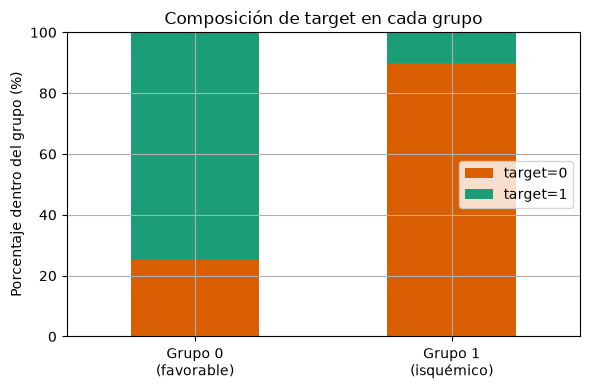

In [12]:
comp = pd.crosstab(lab, y, normalize="index") * 100
comp.index = ["Grupo 0\n(favorable)", "Grupo 1\n(isquémico)"]
comp.columns = ["target=0", "target=1"]
ax = comp.plot(kind="bar", stacked=True, color=["#d95f02", "#1b9e77"], figsize=(6, 4))
ax.set_ylabel("Porcentaje dentro del grupo (%)")
ax.set_xlabel("")
ax.set_title("Composición de target en cada grupo")
ax.set_ylim(0, 100)
ax.legend(title="", loc="center right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### ¿Los grupos coinciden con `target`?

**Sí, en la dirección general, pero no son equivalentes.** La asociación es fuerte: V de Cramér = 0,619 y chi-cuadrado = 392,28 (p ≈ 2,6 × 10⁻⁸⁷, un valor descriptivo porque hay duplicados, no una prueba inferencial formal). El grupo favorable concentra el 74,7 % de los `target=1`; el grupo isquémico concentra el 89,8 % de los `target=0`. Pero el ARI es 0,364: 203 pacientes (19,8 %) caen en la celda “opuesta”.

**Nota sobre la codificación de `target`.** En estos datos, `target=1` tiene el perfil favorable: mayor `thalach`, menor `oldpeak`, menos `exang` y menos `ca`. Eso es consistente con `target=1 = sin enfermedad` en este archivo. Si el curso usa la convención contraria, basta invertir la lectura de la tabla; los grupos y sus perfiles no cambian.

### ¿Qué encontró K-means que la respuesta no dice?

1. **Un eje de gravedad funcional.** El `target` es binario; K-means ordena a los pacientes por capacidad funcional (`thalach`, `exang`, `oldpeak`, `ca`, `slope`, edad). Dentro de `target=0` hay 165 pacientes con perfil favorable (edad 53,7; `thalach` 158,1; `oldpeak` 0,84; `ca` 0,75) y 334 con perfil isquémico. Dentro de `target=1` hay 488 favorables y 38 con perfil de alto riesgo (edad 61,3; `thalach` 129,0; `oldpeak` 1,51; `ca` 0,97).

2. **Heterogeneidad que la etiqueta no distingue.** Esos 38 pacientes con `target=1` y perfil isquémico, y esos 165 con `target=0` y perfil favorable, son los casos que la respuesta binaria no separa. Pueden ser enfermedad silente, subdiagnóstico, errores de codificación o pacientes con enfermedad pero buen rendimiento; este taller no permite decidirlo, pero K-means los hace visibles.

3. **Variables que el `target` no resume.** El grupo isquémico es mayor (58,3 vs 52,2 años), más masculino (76 % vs 66 %) y tiene colesterol y presión algo más altos. El `target` no dice nada de esa combinación; K-means sí la usa para formar los grupos.

En resumen: los grupos **coinciden parcialmente** con `target` (asociación fuerte, V = 0,619), pero **no son la misma cosa** (ARI = 0,364). K-means aporta una noción de gravedad/perfil funcional y detecta subgrupos dentro de cada clase.

## 8. Conclusiones

* **Escalar es indispensable.** Sin escalar, K-means segmenta por colesterol (299 vs 216 mg/dl), la silueta sube a 0,397 por un artefacto de unidades y los grupos casi no se relacionan con `target` (ARI = 0,021). Al estandarizar, todas las variables pesan de forma comparable.
* **K = 2.** Es el mayor valor de silueta (0,170) y el mayor salto de inercia (15,6 % al pasar de K=1 a K=2). K=3 y siguientes mejoran poco la inercia y bajan la silueta. La estructura es débil, así que los grupos deben leerse como segmentos descriptivos, no como clases naturales.
* **Solución estable.** Con `n_init=100`, cinco semillas distintas producen la misma partición (ARI = 1,000).
* **Perfiles claros.** Grupo 0: favorable, joven, alto `thalach`, bajo `oldpeak` y poca angina. Grupo 1: isquémico, mayor, bajo `thalach`, angina de esfuerzo, depresión del ST y más vasos afectados.
* **Cruce con `target`.** Asociación fuerte (V = 0,619) pero no equivalencia (ARI = 0,364; 19,8 % de casos discordantes). K-means encuentra un gradiente de gravedad y heterogeneidad dentro de cada clase que la respuesta binaria no dice.

**Limitaciones.** Los códigos `cp`, `restecg`, `slope` y `thal` son categorías nominales tratadas como números, lo que impone un orden artificial; una alternativa sería codificarlas con one-hot. Hay 723 duplicados exactos, de modo que el tamaño efectivo es menor y los p-valores no deben interpretarse como inferencia. La silueta de 0,170 indica solapamiento. Finalmente, la dirección de `target` debe confirmarse con la documentación del curso.